# ECE 3715 Mini-Project 3

In [1]:
import time
t_start = time.perf_counter()

import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate, stats
from mp3lib import (sample_mean_cov, is_valid_covariance, gaussian_pdf,
                    whitening_matrix, lmmse_weights)

SEED = 199593370   # drawn once, do not change
rng = np.random.default_rng(SEED)

# One generator per step, spawned once here. No default_rng calls below this cell.
rng1 = rng.spawn(1)[0]
rng2 = rng.spawn(1)[0]
rng3 = rng.spawn(1)[0]
rng4 = rng.spawn(1)[0]
rng5 = rng.spawn(1)[0]
rng6 = rng.spawn(1)[0]
rng7 = rng.spawn(1)[0]
rng8 = rng.spawn(1)[0]

print(f"Seed = {SEED}")

Seed = 199593370


---
# Step 1: Two variables at once

Joint density: $f_{XY}(x,y) = x + y$ for $0 \le x \le 1,\ 0 \le y \le 1$, and zero elsewhere.

### Verify by hand
The density is non-negative on the unit square, and it integrates to one:
$$
\int_0^1\!\!\int_0^1 (x+y)\,dy\,dx
= \int_0^1 \left[xy + \tfrac{y^2}{2}\right]_0^1 dx
= \int_0^1 \left(x + \tfrac12\right) dx
= \tfrac12 + \tfrac12 = 1 
$$

In [2]:
f_xy = lambda y, x: x + y   # dblquad expects f(y, x)

# 2D quadrature over the unit square
total, total_err = integrate.dblquad(f_xy, 0, 1, 0, 1)
print(f"Integral of f_XY over unit square = {total:.12f}  (|1 - integral| = {abs(1-total):.2e})")

Integral of f_XY over unit square = 1.000000000000  (|1 - integral| = 0.00e+00)


### Marginals by hand
$$
f_X(x) = \int_0^1 (x+y)\,dy = \left[xy + \tfrac{y^2}{2}\right]_0^1 = x + \tfrac12, \qquad
f_Y(y) = \int_0^1 (x+y)\,dx = \left[\tfrac{x^2}{2}+xy\right]_0^1 = y + \tfrac12 
$$
By symmetry the two marginals have the same form. Below we integrate the joint density over the other variable on a grid (trapezoid rule) and compare.

In [3]:
# Evaluate the joint density on a grid
g = np.linspace(0, 1, 1001)
XX, YY = np.meshgrid(g, g, indexing="ij")   # XX[i, j] = g[i], YY[i, j] = g[j]
F = XX + YY

# Numerical marginals: integrate out the other variable
fX_num = np.trapezoid(F, g, axis=1)   # integrate over y
fY_num = np.trapezoid(F, g, axis=0)   # integrate over x
f_marg = g + 0.5                      # analytic marginal (same for X and Y)

print(f"max |f_X numeric - analytic| = {np.max(np.abs(fX_num - f_marg)):.2e}")
print(f"max |f_Y numeric - analytic| = {np.max(np.abs(fY_num - f_marg)):.2e}")
print(f"f_X(0.3) analytic = {0.3 + 0.5:.4f}, numeric = {np.interp(0.3, g, fX_num):.6f}")

max |f_X numeric - analytic| = 2.22e-16
max |f_Y numeric - analytic| = 8.88e-16
f_X(0.3) analytic = 0.8000, numeric = 0.800000


### Conditional density of $Y$ given $X=x$
$$
f_{Y|X}(y \mid x) = \frac{f_{XY}(x,y)}{f_X(x)} = \frac{x+y}{x+\tfrac12}, \qquad 0 \le y \le 1 
$$
At $x = 0.3$: $f_{Y|X}(y \mid 0.3) = \dfrac{0.3 + y}{0.8}$, a straight line over the unit interval.

### $x=0.3$ conditional density plot in Figure 1(c)

In [4]:
x0 = 0.3
f_cond = lambda y: (x0 + y) / (x0 + 0.5)

print(f"Conditional density endpoints: {f_cond(0):.3f}, {f_cond(1):.3f}")
cond_int, _ = integrate.quad(f_cond, 0, 1)
print(f"Integral of f(y | x=0.3) over [0,1] = {cond_int:.12f}  (|1 - integral| = {abs(1-cond_int):.2e})")

Conditional density endpoints: 0.375, 1.625
Integral of f(y | x=0.3) over [0,1] = 1.000000000000  (|1 - integral| = 1.11e-16)


### Moments
$$
E[X] = \int_0^1 x\left(x+\tfrac12\right)dx = \tfrac13 + \tfrac14 = \tfrac{7}{12}, \qquad E[Y] = \tfrac{7}{12}\ 
$$
$$
E[X^2] = \int_0^1 x^2\left(x+\tfrac12\right)dx = \tfrac14 + \tfrac16 = \tfrac{5}{12}, \qquad
\mathrm{Var}(X) = \tfrac{5}{12} - \left(\tfrac{7}{12}\right)^2 = \tfrac{60-49}{144} = \tfrac{11}{144}
$$
$$
E[XY] = \int_0^1\!\!\int_0^1 xy(x+y)\,dy\,dx = \int_0^1\!\!\int_0^1 (x^2y + xy^2)\,dy\,dx = \tfrac16 + \tfrac16 = \tfrac13
$$
$$
\mathrm{Cov}(X,Y) = \tfrac13 - \tfrac{49}{144} = \tfrac{48-49}{144} = -\tfrac{1}{144}, \qquad
\rho = \frac{-1/144}{11/144} = -\tfrac{1}{11}
$$

In [5]:
# Analytic values from the derivation above
EX_a, EXY_a, VarX_a = 7/12, 1/3, 11/144
Cov_a = EXY_a - EX_a**2
rho_a = Cov_a / VarX_a

# 2D quadrature
q = lambda g: integrate.dblquad(lambda y, x: g(x, y) * (x + y), 0, 1, 0, 1)[0]
EX_q  = q(lambda x, y: x)
EY_q  = q(lambda x, y: y)
EXY_q = q(lambda x, y: x * y)
EX2_q = q(lambda x, y: x**2)
VarX_q = EX2_q - EX_q**2
Cov_q  = EXY_q - EX_q * EY_q

rho_q  = Cov_q / VarX_q   
# Var(Y) = Var(X) by symmetry

print(f"{'quantity':<10}{'analytic':>14}{'quadrature':>14}{'|diff|':>12}")
for name, a, n in [("E[X]", EX_a, EX_q), ("E[Y]", EX_a, EY_q), ("E[XY]", EXY_a, EXY_q),
                   ("Var(X)", VarX_a, VarX_q), ("Cov(X,Y)", Cov_a, Cov_q), ("rho", rho_a, rho_q)]:
    print(f"{name:<10}{a:>14.7f}{n:>14.7f}{abs(a-n):>12.1e}")

quantity        analytic    quadrature      |diff|
E[X]           0.5833333     0.5833333     1.1e-16
E[Y]           0.5833333     0.5833333     1.1e-16
E[XY]          0.3333333     0.3333333     1.1e-16
Var(X)         0.0763889     0.0763889     5.6e-17
Cov(X,Y)      -0.0069444    -0.0069444     2.8e-16
rho           -0.0909091    -0.0909091     3.7e-15


### Rejection sampling

The uniform proposal density is $g=1$ on the unit square. Since $f$ attains its maximum at $(1,1)$, the smallest valid bound is $M=2$. We accept when $ule (x+y)/M$ for an independent $usim U(0,1)$, giving an expected acceptance probability of $1/M$.

For means, divide the sample standard deviation of the summand by $\sqrt N$. For variance and covariance, use the centered square and centered product as the first-order summands. To estimate the correlation SE for this non-Gaussian distribution, apply the delta method to $c/\sqrt{v_xv_y}$, where $c$ is covariance and $v_x,v_y$ are variances. With sample-standardized variables $z_x,z_y$, the resulting summand is $z_xz_y-\hat\rho(z_x^2+z_y^2)/2$.

In [6]:
def sample_joint(n, rng, M=2.0):
    # Generate proposals in vectorized batches.
    accepted = []
    n_prop = n_have = 0
    while n_have < n:
        m = int(1.1 * M * (n - n_have)) + 1000
        xy = rng.random((m, 2))
        keep = rng.random(m) <= xy.sum(axis=1) / M
        accepted.append(xy[keep])
        n_prop += m
        n_have += keep.sum()
    return np.vstack(accepted)[:n], n_have / n_prop, n_prop

def report_comparison(label, theory, estimate, se):
    print(f"{label:<14}{theory:>13.6g}{estimate:>13.6g}{estimate-theory:>16.3e}{se:>13.3e}")

comparison_header = f"{'quantity':<14}{'theory':>13}{'estimate':>13}{'est. - theory':>16}{'SE':>13}"

def mean_se(values):
    return values.std(ddof=1) / np.sqrt(len(values))

def correlation_and_se(x, y):
    zx = (x - x.mean()) / x.std()
    zy = (y - y.mean()) / y.std()
    correlation = np.mean(zx * zy)
    influence = zx * zy - 0.5 * correlation * (zx**2 + zy**2)
    return correlation, mean_se(influence)

N1 = 10**6
S1, acc_rate, n_prop = sample_joint(N1, rng1)
xs, ys = S1.T
xc, yc = xs - xs.mean(), ys - ys.mean()
rho_s, se_rho_s = correlation_and_se(xs, ys)

print(f"Accepted sample size = {N1:,}. Acceptance rate uses all {n_prop:,} proposals.")
print(comparison_header)
report_comparison("acceptance", 0.5, acc_rate, np.sqrt(0.25 / n_prop))
for label, truth, values in [
    ("E[X]", EX_a, xs), ("E[Y]", EX_a, ys), ("E[XY]", EXY_a, xs * ys),
    ("Var(X)", VarX_a, xc**2), ("Cov(X,Y)", Cov_a, xc * yc),
]:
    report_comparison(label, truth, values.mean(), mean_se(values))
report_comparison("rho", rho_a, rho_s, se_rho_s)

Accepted sample size = 1,000,000. Acceptance rate uses all 2,201,000 proposals.
quantity             theory     estimate   est. - theory           SE
acceptance              0.5     0.500584       5.838e-04    3.370e-04
E[X]               0.583333     0.583759       4.258e-04    2.764e-04
E[Y]               0.583333     0.583175      -1.584e-04    2.766e-04
E[XY]              0.333333     0.333479       1.460e-04    2.358e-04
Var(X)            0.0763889    0.0764181       2.925e-05    7.639e-05
Cov(X,Y)        -0.00694444  -0.00695437      -9.929e-06    7.486e-05
rho              -0.0909091   -0.0909627      -5.366e-05    9.708e-04


### Figure 1

<ipython-input-7-f6077da22e13>:24: MatplotlibDeprecationWarning: The width parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(width) instead.
  plt.tight_layout(); plt.show()
<ipython-input-7-f6077da22e13>:24: MatplotlibDeprecationWarning: The height parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(height) instead.
  plt.tight_layout(); plt.show()
<ipython-input-7-f6077da22e13>:24: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.tight_layout(); plt.show()
<ipython-input-7-f6077da22e13>:24: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.tight_layout(); plt.show()
<ipython-input-7-f6077da22e13>:24: MatplotlibDeprecationWarning: The x0 parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use 

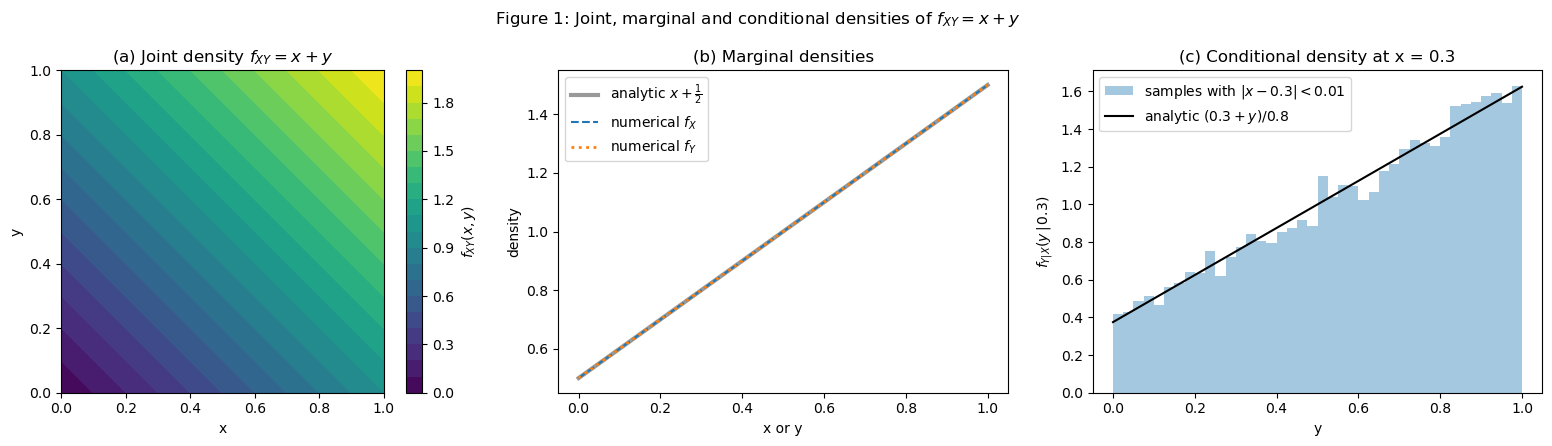

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

# (a) joint density
cf = ax[0].contourf(XX, YY, F, levels=20, cmap="viridis")
fig.colorbar(cf, ax=ax[0], label=r"$f_{XY}(x,y)$")
ax[0].set(xlabel="x", ylabel="y", title="(a) Joint density $f_{XY}=x+y$")
ax[0].set_aspect("equal")

# (b) marginals: analytic vs numerical
ax[1].plot(g, f_marg, "k-", lw=3, alpha=0.4, label=r"analytic $x+\frac{1}{2}$")
ax[1].plot(g, fX_num, "C0--", label=r"numerical $f_X$")
ax[1].plot(g, fY_num, "C1:", lw=2, label=r"numerical $f_Y$")
ax[1].set(xlabel="x or y", ylabel="density", title="(b) Marginal densities")
ax[1].legend()

# (c) conditional at x = 0.3, with a histogram of samples in a thin slice near x = 0.3
sl = np.abs(xs - x0) < 0.01
ax[2].hist(ys[sl], bins=40, density=True, alpha=0.4, label=r"samples with $|x-0.3|<0.01$")
ax[2].plot(g, f_cond(g), "k-", label=r"analytic $(0.3+y)/0.8$")
ax[2].set(xlabel="y", ylabel=r"$f_{Y|X}(y\,|\,0.3)$", title="(c) Conditional density at x = 0.3")
ax[2].legend()

fig.suptitle("Figure 1: Joint, marginal and conditional densities of $f_{XY}=x+y$")
plt.tight_layout(); plt.show()

**Interpretation of Figure 1.** The straight joint-density contours follow $x+y=\mathrm{constant}$. The numerical marginals overlay the analytic curve to rounding precision. The increasing conditional curve shows that large $y$ is more likely given $X=0.3$, and the thin-slice histogram follows the same upward trend.

### Why the correlation is negative

The conditional mean $E[Y\mid X=x]=(x/2+1/3)/(x+1/2)$ decreases with $x$ because its derivative is $-1/[12(x+1/2)^2]$. At small $x$, the $y$ term drives the conditional density toward larger $y$, whereas increasing $x$ makes the conditional density more uniform and lowers its mean.

---
# Step 2: Uncorrelated does not mean independent

### Covariance by hand
Let $X \sim U(-1,1)$, so $f_X(x) = \tfrac12$ on $[-1,1]$, and let $Y = X^2$
$$
E[X] = 0, \qquad E[X^3] = \int_{-1}^{1} \tfrac12 x^3\,dx = \left. \frac{1}{8}  x^4 \right\rvert_{-1}^{1} = 0 \quad 
$$
$$
\mathrm{Cov}(X,Y) = E[XY] - E[X]E[Y] = E[X^3] - 0 \cdot E[X^2] = 0 
$$
$$
E[Y]=E[X^2]=\tfrac12\left[\tfrac{x^3}{3}\right]_{-1}^{1}=\tfrac13=\mathrm{Var}(X),\qquad
E[Y^2]=E[X^4]=\tfrac12\left[\tfrac{x^5}{5}\right]_{-1}^{1}=\tfrac15.
$$
Thus $\mathrm{Var}(Y)=\tfrac15-(\tfrac13)^2=\tfrac4{45}$.

In [8]:
N2 = 10**7
x2 = rng2.uniform(-1, 1, N2)
y2 = x2**2
r2, se_r2 = correlation_and_se(x2, y2)
xc2, yc2 = x2 - x2.mean(), y2 - y2.mean()

print(f"N = {N2:,}, 1/sqrt(N) = {1/np.sqrt(N2):.2e}, correlation/SE = {r2/se_r2:.2f}")
print(comparison_header)
report_comparison("rho", 0, r2, se_r2)
for label, truth, values in [
    ("E[Y]", 1/3, y2), ("Var(X)", 1/3, xc2**2),
    ("Var(Y)", 4/45, yc2**2), ("Cov(X,Y)", 0, xc2 * yc2),
]:
    report_comparison(label, truth, values.mean(), mean_se(values))
del xc2, yc2

N = 10,000,000, 1/sqrt(N) = 3.16e-04, correlation/SE = 0.14
quantity             theory     estimate   est. - theory           SE
rho                       0  5.41714e-05       5.417e-05    3.963e-04
E[Y]               0.333333      0.33346       1.267e-04    9.429e-05
Var(X)             0.333333      0.33346       1.267e-04    9.429e-05
Var(Y)            0.0888889    0.0889085       1.961e-05    3.005e-05
Cov(X,Y)                  0  9.32747e-06       9.327e-06    6.824e-05


### Dependence in narrow bins

$Y=X^2$ gives $\operatorname{Var}(Y\mid X=x)=0$ at each $x$. Within a bin centered at $c$ with width $w$, write $X=c+U$ with $U\sim U(-w/2,w/2)$. The odd moments of $U$ vanish, so
$$
\operatorname{Var}(X^2\mid \text{bin})
=4c^2 E[U^2]+E[U^4]-(E[U^2])^2
=\frac{c^2w^2}{3}+\frac{w^4}{180}.
$$
The positive bin variance comes from mixing nearby values of $X$ and tends to zero as the bin width shrinks.

In [9]:
def binned_cond_var(x, y, edges):
    width = edges[1] - edges[0]
    centers = 0.5 * (edges[:-1] + edges[1:])
    idx = np.clip(np.floor((x - edges[0]) / width).astype(int), 0, len(centers) - 1)
    count = np.bincount(idx, minlength=len(centers))
    residual = y - (centers**2 + width**2 / 12)[idx]
    squared = residual**2
    mean_squared = np.bincount(idx, weights=squared) / count
    mean_resid = np.bincount(idx, weights=residual) / count
    estimate = (mean_squared - mean_resid**2) * count / (count - 1)
    fourth = np.bincount(idx, weights=squared**2) / count
    se = np.sqrt(np.maximum(fourth - mean_squared**2, 0) / (count - 1))
    theory = centers**2 * width**2 / 3 + width**4 / 180
    return centers, estimate, theory, se

print(f"Unconditional Var(Y) = {4/45:.6f}")
print("Bin with the largest observed conditional variance at each resolution")
print(comparison_header)
for n_bins in (20, 200, 2000):
    edges = np.linspace(-1, 1, n_bins + 1)
    centers, estimates, theory, se = binned_cond_var(x2, y2, edges)
    j = estimates.argmax()
    report_comparison(f"{n_bins} bins", theory[j], estimates[j], se[j])
    if n_bins == 200:
        centers2, cv200, cv_theory, cv_se = centers, estimates, theory, se

Unconditional Var(Y) = 0.088889
Bin with the largest observed conditional variance at each resolution
quantity             theory     estimate   est. - theory           SE
20 bins          0.00300889   0.00300708      -1.804e-06    3.812e-06
200 bins        3.30009e-05  3.29634e-05      -3.750e-08    1.312e-07
2000 bins       3.29677e-07  3.39023e-07       9.346e-09    4.141e-09


### Figure 2

<ipython-input-10-4b31fe4e7a43>:21: MatplotlibDeprecationWarning: The width parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(width) instead.
  plt.tight_layout(); plt.show()
<ipython-input-10-4b31fe4e7a43>:21: MatplotlibDeprecationWarning: The height parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(height) instead.
  plt.tight_layout(); plt.show()
<ipython-input-10-4b31fe4e7a43>:21: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.tight_layout(); plt.show()
<ipython-input-10-4b31fe4e7a43>:21: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.tight_layout(); plt.show()


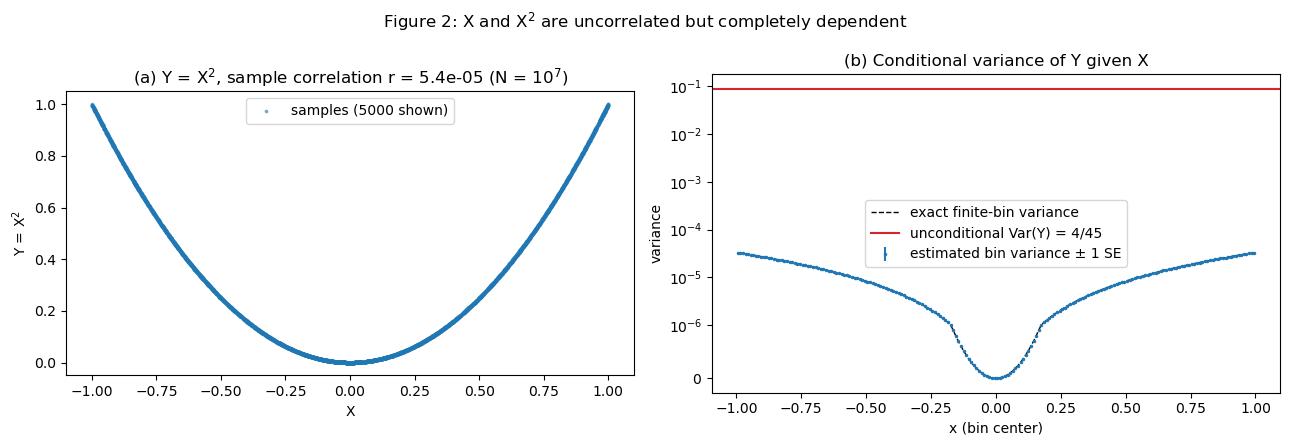

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# (a) scatter of a subsample (plotting 10^7 points is slow and adds nothing)
sub = slice(0, 5000)
ax[0].scatter(x2[sub], y2[sub], s=3, alpha=0.5, label="samples (5000 shown)")
ax[0].set(xlabel="X", ylabel=r"Y = X$^2$",
          title=f"(a) Y = X$^2$, sample correlation r = {r2:.1e} (N = 10$^7$)")
ax[0].legend()
ax[0].set_aspect("equal")

# (b) binned conditional variance vs the unconditional variance
ax[1].errorbar(centers2, cv200, yerr=cv_se, fmt="C0.", ms=3,
               label="estimated bin variance ± 1 SE")
ax[1].plot(centers2, cv_theory, "k--", lw=1, label="exact finite-bin variance")
ax[1].axhline(4/45, color="C3", label="unconditional Var(Y) = 4/45")
ax[1].set(xlabel="x (bin center)", ylabel="variance", title="(b) Conditional variance of Y given X")
ax[1].set_yscale("symlog", linthresh=1e-6)
ax[1].legend()

fig.suptitle("Figure 2: X and X$^2$ are uncorrelated but completely dependent")
plt.tight_layout(); plt.show()

**Interpretation of Figure 2.** The parabola determines $Y$ from $X$ exactly, even though the measured correlation is near zero. The conditional variance in the bins follows the finite-bin prediction and lies far below the unconditional variance. The reported maximum shrinks rapidly as the bins get narrower, consistent with zero pointwise conditional variance.

### What correlation measures

Correlation measures linear association, so the opposite slopes on the two halves of this symmetric parabola cancel and yield zero correlation.

### The Gaussian pair

Use ten bins on each axis with boundaries at the theoretical standard normal deciles. Integrating the empirical joint density and the product of the empirical marginal densities over a cell gives the joint cell frequency and the product of its marginal frequencies. Under independence the leading standard error of their difference is $\sqrt{p(1-p)q(1-q)/N}$ for marginal cell probabilities $p,q$. The chi-square test summarizes the discrepancies across all cells.

In [11]:
N2g = 10**6
G = rng2.multivariate_normal(np.zeros(2), np.eye(2), size=N2g)
cuts = stats.norm.ppf(np.arange(1, 10) / 10)
ga, gb = (np.searchsorted(cuts, column) for column in G.T)
table = np.bincount(10 * ga + gb, minlength=100).reshape(10, 10)
joint = table / N2g
p, q = joint.sum(axis=1), joint.sum(axis=0)
product = np.outer(p, q)
cell_se = np.sqrt(np.outer(p * (1 - p), q * (1 - q)) / N2g)
largest = np.unravel_index(np.argmax(np.abs(joint - product)), joint.shape)
chi2, p_value, dof, _ = stats.chi2_contingency(table)
gaussian_r, gaussian_r_se = correlation_and_se(*G.T)

print(comparison_header)
report_comparison("largest cell", product[largest], joint[largest], cell_se[largest])
report_comparison("Gaussian rho", 0, gaussian_r, gaussian_r_se)
print(f"Max relative cell discrepancy = {np.max(np.abs(joint-product)/product):.2%}")
print(f"Chi-square = {chi2:.2f} on {dof} degrees of freedom, p = {p_value:.3g}")

quantity             theory     estimate   est. - theory           SE
largest cell      0.0100603     0.009771      -2.893e-04    9.024e-05
Gaussian rho              0  0.000790891       7.909e-04    1.000e-03
Max relative cell discrepancy = 2.88%
Chi-square = 75.38 on 81 degrees of freedom, p = 0.655


**Interpretation.** The Gaussian cell discrepancies are consistent with sampling noise across the grid, and the chi-square result provides a joint check of the factorization.

For a jointly Gaussian vector, zero cross-covariance makes the covariance diagonal, so the quadratic form in the exponent splits into a sum and the joint density factors into its marginal densities. The deterministic parabola shows why zero covariance alone cannot establish independence. In engineering, the joint Gaussian model is what lets us treat decorrelated noise channels as independent.

---
# Step 3: The covariance matrix and how well you can estimate it

$$
\Sigma = \begin{bmatrix} 4 & 2 & 1 & 0 \\ 2 & 5 & 2 & 1 \\ 1 & 2 & 3 & 1 \\ 0 & 1 & 1 & 2 \end{bmatrix}
$$

### Is $\Sigma$ a valid covariance matrix?
A covariance matrix must be symmetric and positive semidefinite (all eigenvalues $\ge 0$). We check with `is_valid_covariance` from `mp3lib.py`, which uses `eigvalsh` with a small tolerance for rounding.

In [12]:
Sigma3 = np.array([[4, 2, 1, 0],
                   [2, 5, 2, 1],
                   [1, 2, 3, 1],
                   [0, 1, 1, 2]], dtype=float)

eig3 = np.linalg.eigvalsh(Sigma3)   # eigvalsh: real eigenvalues for symmetric matrices
print(f"Symmetric: {np.array_equal(Sigma3, Sigma3.T)}")
print(f"Eigenvalues: {np.round(eig3, 4)}  (all positive: {np.all(eig3 > 0)})")
print(f"Determinant: {np.linalg.det(Sigma3):.6f}\n")

# Test cases for is_valid_covariance
A_nonsym = np.array([[2.0, 1.0], [0.0, 2.0]])          # not symmetric
A_negeig = np.array([[1.0, 2.0], [2.0, 1.0]])          # symmetric, eigenvalues -1 and 3
A_round  = np.array([[1.0, 1.0], [1.0, 1.0]]) - 1e-14 * np.eye(2)  # PSD up to rounding (eig ~ -1e-14)

tests = [("Sigma (4x4)", Sigma3), ("non-symmetric", A_nonsym),
         ("negative eigenvalue", A_negeig), ("rounding-level negative eig", A_round)]
for name, M in tests:
    valid = is_valid_covariance(M)
    if np.array_equal(M, M.T):
        ev = np.linalg.eigvalsh(M)
        print(f"{name:<28} valid = {valid!s:<5}  eigenvalues = {np.round(ev, 14)}")
    else:
        print(f"{name:<28} valid = {valid!s:<5}  fails symmetry")

Symmetric: True
Eigenvalues: [1.2649 1.7882 3.0981 7.8488]  (all positive: True)
Determinant: 55.000000

Sigma (4x4)                  valid = True   eigenvalues = [1.26487889 1.78819531 3.09808432 7.84884147]
non-symmetric                valid = False  fails symmetry
negative eigenvalue          valid = False  eigenvalues = [-1.  3.]
rounding-level negative eig  valid = True   eigenvalues = [-1.e-14  2.e+00]


### Sampling and single-draw estimates
We draw zero-mean Gaussian samples with covariance $\Sigma$ (library generator) and estimate $\hat\Sigma$ with `sample_mean_cov`. The error is measured with the Frobenius norm $\|\hat\Sigma - \Sigma\|_F = \sqrt{\sum_{ij} (\hat\Sigma_{ij} - \Sigma_{ij})^2}$.

In [13]:
Ns = np.array([10**2, 10**3, 10**4, 10**5, 10**6])
mu3 = np.zeros(4)

def cov_error(N, rng):
    # One estimate of Sigma from N samples, returned as a Frobenius-norm error
    X = rng.multivariate_normal(mu3, Sigma3, size=N)
    _, S_hat = sample_mean_cov(X)
    return np.linalg.norm(S_hat - Sigma3, "fro")

single = np.array([cov_error(N, rng3) for N in Ns])
print(f"{'N':>9}{'single-draw error':>20}{'sqrt(N)*error':>16}")
for N, e in zip(Ns, single):
    print(f"{N:>9d}{e:>20.4f}{np.sqrt(N)*e:>16.2f}")

        N   single-draw error   sqrt(N)*error
      100              1.2805           12.80
     1000              0.3462           10.95
    10000              0.1700           17.00
   100000              0.0595           18.80
  1000000              0.0153           15.26


### Averaging over repetitions
One draw per $N$ is too noisy to see the rate, so we repeat the estimate many times at each $N$ and average the error. Error bars on the plot are $\pm 1$ standard deviation of the single-draw error across repetitions; the printed SE is the standard error of the average. The slope is fitted by least squares on $\log_{10}$(error) vs $\log_{10} N$.

In [14]:
reps = {10**2: 200, 10**3: 200, 10**4: 100, 10**5: 30, 10**6: 10}

avg_err, std_err, se_err = [], [], []
for N in Ns:
    errs = np.array([cov_error(N, rng3) for _ in range(reps[N])])
    avg_err.append(errs.mean())
    std_err.append(errs.std(ddof=1))
    se_err.append(std_err[-1] / np.sqrt(reps[N]))
avg_err, std_err, se_err = map(np.array, (avg_err, std_err, se_err))

# Fit log10(error) = slope * log10(N) + intercept
slope_avg, icpt_avg = np.polyfit(np.log10(Ns), np.log10(avg_err), 1)
slope_one, icpt_one = np.polyfit(np.log10(Ns), np.log10(single), 1)

print(f"{'N':>9}{'reps':>6}{'avg error':>12}{'SE':>10}{'sqrt(N)*avg':>14}{'sqrt(N)*single':>16}")
for N, e, se, e1 in zip(Ns, avg_err, se_err, single):
    print(f"{N:>9d}{reps[N]:>6d}{e:>12.4f}{se:>10.4f}{np.sqrt(N)*e:>14.2f}{np.sqrt(N)*e1:>16.2f}")
log_n_centered = np.log10(Ns) - np.log10(Ns).mean()
slope_weights = log_n_centered / np.sum(log_n_centered**2)
slope_se = np.linalg.norm(slope_weights * se_err / (avg_err * np.log(10)))
print(comparison_header)
report_comparison("averaged slope", -0.5, slope_avg, slope_se)
print(f"Theoretical error reduction per decade = {np.sqrt(10):.3f}")
print(f"Measured error reduction per decade = {10**(-slope_avg):.3f}")
print("Comparison with the handout's approximate average errors")
print(comparison_header)
for N, expected, estimate, se in zip(Ns, [1.56, 0.49, 0.16, 0.046, 0.016], avg_err, se_err):
    report_comparison(f"N={N:,}", expected, estimate, se)
print(f"Scaled SEs (sqrt(N) times the SE of the average) = {np.round(np.sqrt(Ns)*se_err, 2)}")
print(f"Fitted slope, single-draw curve: {slope_one:.3f}")
sq = np.sqrt(Ns) * avg_err
print(f"sqrt(N)*avg error: mean {sq.mean():.2f}, spread (max-min)/mean = {(sq.max()-sq.min())/sq.mean()*100:.1f}%")

        N  reps   avg error        SE   sqrt(N)*avg  sqrt(N)*single
      100   200      1.5594    0.0381         15.59           12.80
     1000   200      0.4968    0.0127         15.71           10.95
    10000   100      0.1613    0.0055         16.13           17.00
   100000    30      0.0495    0.0025         15.65           18.80
  1000000    10      0.0168    0.0016         16.81           15.26
quantity             theory     estimate   est. - theory           SE
averaged slope         -0.5    -0.493641       6.359e-03    9.102e-03
Theoretical error reduction per decade = 3.162
Measured error reduction per decade = 3.116
Comparison with the handout's approximate average errors
quantity             theory     estimate   est. - theory           SE
N=100                  1.56      1.55944      -5.629e-04    3.813e-02
N=1,000                0.49     0.496769       6.769e-03    1.271e-02
N=10,000               0.16     0.161317       1.317e-03    5.493e-03
N=100,000             0.

### Figure 3

<ipython-input-15-d683683b47bb>:11: MatplotlibDeprecationWarning: The width parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(width) instead.
  plt.tight_layout(); plt.show()
<ipython-input-15-d683683b47bb>:11: MatplotlibDeprecationWarning: The height parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(height) instead.
  plt.tight_layout(); plt.show()
<ipython-input-15-d683683b47bb>:11: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.tight_layout(); plt.show()
<ipython-input-15-d683683b47bb>:11: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.tight_layout(); plt.show()
<ipython-input-15-d683683b47bb>:11: MatplotlibDeprecationWarning: The x0 parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12.

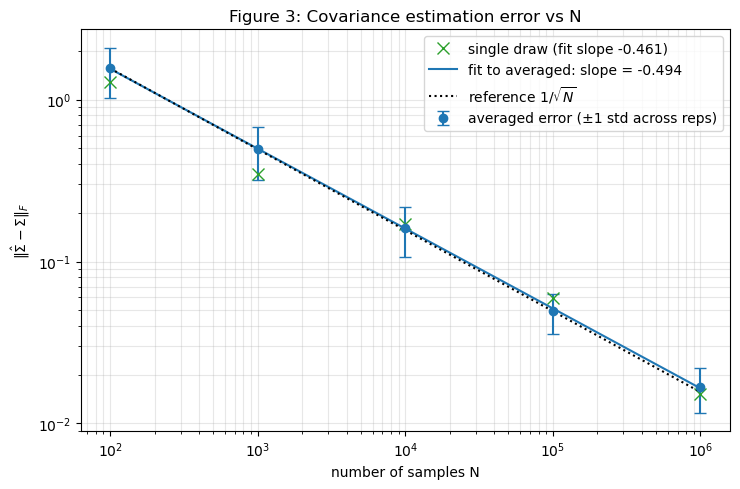

In [15]:
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.errorbar(Ns, avg_err, yerr=std_err, fmt="o", capsize=4, label="averaged error (±1 std across reps)")
ax.plot(Ns, single, "x", color="C2", ms=9, label=f"single draw (fit slope {slope_one:.3f})")
Nfit = np.logspace(2, 6, 50)
ax.plot(Nfit, 10**icpt_avg * Nfit**slope_avg, "C0-", label=f"fit to averaged: slope = {slope_avg:.3f}")
ax.plot(Nfit, avg_err[0] * np.sqrt(Ns[0] / Nfit), "k:", label=r"reference $1/\sqrt{N}$")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set(xlabel="number of samples N", ylabel=r"$\|\hat\Sigma - \Sigma\|_F$",
       title="Figure 3: Covariance estimation error vs N")
ax.legend(); ax.grid(True, which="both", alpha=0.3)
plt.tight_layout(); plt.show()

**Interpretation of Figure 3.** The averaged points follow a straight line on log-log axes. The fitted slope and its standard error quantify the agreement with $-1/2$, and the scaled errors in the table stay near a constant. The largest scaled error occurs at the largest sample size, where the repetition count is smallest and the average has the largest scaled standard error. A single-draw curve gives an unstable slope because each of its points has the full sampling spread shown by the error bars.

### How much data does a bigger covariance need?

A symmetric $d\times d$ matrix has $d$ diagonal entries and $d(d-1)/2$ distinct off-diagonal entries, for a total of $d(d+1)/2$. As a planning estimate, assume that the squared error relative to $\|\Sigma\|_F^2$ contributes comparably per parameter across the two problems. Under that assumption, the measured power law implies $\mathrm{relative\ error}\propto \sqrt{d(d+1)/2}\,N^{\text{slope}}$. The required sample count depends on the actual covariance of the larger array.

In [16]:
def covariance_parameters(d):
    return d * (d + 1) // 2

N_ref = 10**4
p4, p100 = covariance_parameters(4), covariance_parameters(100)
N_100 = N_ref * (p100 / p4)**(-0.5 / slope_avg)
print(f"Free parameters: d = 4 -> {p4}, d = 100 -> {p100}")
print(f"Relative Frobenius error at N = {N_ref:,}, d = 4: "
      f"{avg_err[Ns == N_ref][0] / np.linalg.norm(Sigma3, 'fro'):.4f}")
print(f"Sample count extrapolated using measured slope {slope_avg:.4f}: {N_100:.2e}")

Free parameters: d = 4 -> 10, d = 100 -> 5050
Relative Frobenius error at N = 10,000, d = 4: 0.0185
Sample count extrapolated using measured slope -0.4936: 5.47e+06


### Why this matters for a 100-element radar

A radar needs to estimate many covariance entries from a window short enough that the interference stays approximately stationary, and the centered estimate has rank at most $N-1$. Diagonal loading adds a positive multiple of the identity so the array processor can work with a better-conditioned covariance estimate.

---
# Step 4. Linear transformations of random vectors

For a constant matrix $A$ and a constant vector $b$, linearity of expectation gives
$$
\mu_y=E[A\mathbf{x}+b]=AE[\mathbf{x}]+b=A\mu_x+b.
$$
The centered output is $\mathbf{y}-\mu_y=A(\mathbf{x}-\mu_x)$, so
$$
\begin{aligned}
\Sigma_y &= E[(\mathbf{y}-\mu_y)(\mathbf{y}-\mu_y)^T]\\
&= E[A(\mathbf{x}-\mu_x)(\mathbf{x}-\mu_x)^T A^T]\\
&= A\Sigma_x A^T.
\end{aligned}
$$

The exercise specifies no offset, so take $b=0$. With $\mu_x=[1,-2]^T$ and $\Sigma_x=\begin{bmatrix}4&2\\2&4\end{bmatrix}$, the first transform gives
$$
\begin{aligned}
A_1\mu_x
&=\begin{bmatrix}1-4\\-2\\1+2\end{bmatrix}
 =\begin{bmatrix}-3\\-2\\3\end{bmatrix},\qquad
A_1\Sigma_x
=\begin{bmatrix}8&10\\2&4\\2&-2\end{bmatrix},\\
\Sigma_{y_1}&=\begin{bmatrix}8&10\\2&4\\2&-2\end{bmatrix}
\begin{bmatrix}1&0&1\\2&1&-1\end{bmatrix}
=\begin{bmatrix}28&10&-2\\10&4&-2\\-2&-2&4\end{bmatrix}.
\end{aligned}
$$
Since $\Sigma_x$ is positive definite, $A_1\Sigma_x A_1^T=(A_1\Sigma_x^{1/2})(A_1\Sigma_x^{1/2})^T$ has rank $\operatorname{rank}(A_1)=2$. Every output lies on the plane $y_1-3y_2-y_3=0$ because the third row of $A_1$ equals its first row minus three times its second.

For the second transform,
$$
\begin{aligned}
A_2\mu_x&=\begin{bmatrix}1-2\\2-4\end{bmatrix}
=\begin{bmatrix}-1\\-2\end{bmatrix},\qquad
A_2\Sigma_x=\begin{bmatrix}6&6\\12&12\end{bmatrix},\\
\Sigma_{y_2}&=\begin{bmatrix}6&6\\12&12\end{bmatrix}
\begin{bmatrix}1&2\\1&2\end{bmatrix}
=\begin{bmatrix}12&24\\24&48\end{bmatrix}.
\end{aligned}
$$
The output is $(X_1+X_2)[1,2]^T$, so it lies on the line $y_2=2y_1$ and the covariance has rank one. In either case a zero determinant makes the normalizing factor undefined and the covariance linear system singular, so there is no Gaussian density with respect to volume in the full output space.

For Gaussian samples, $\operatorname{SE}(\hat\mu_i)=\sqrt{\Sigma_{ii}/N}$ and $\operatorname{SE}(\hat\Sigma_{ij})=\sqrt{(\Sigma_{ii}\Sigma_{jj}+\Sigma_{ij}^2)/(N-1)}$ for the unbiased covariance estimate; the second expression follows from the Gaussian fourth moments.

In [17]:
def report_covariance(theory, estimate, n):
    # Exact sampling SE of an unbiased covariance entry for Gaussian data.
    diagonal = np.diag(theory)
    se = np.sqrt((np.outer(diagonal, diagonal) + theory**2) / (n - 1))
    print(comparison_header)
    for i, j in zip(*np.triu_indices(len(theory))):
        report_comparison(f"cov[{i+1},{j+1}]", theory[i, j], estimate[i, j], se[i, j])
    error = np.linalg.norm(estimate - theory, "fro")
    print(f"Frobenius error = {error:.6g}")

N4 = 10**6
mu4 = np.array([1, -2])
Sigma2 = np.array([[4., 2.], [2., 4.]])
X4 = rng4.multivariate_normal(mu4, Sigma2, size=N4)
A_plane = np.array([[1, 2], [0, 1], [1, -1]])
A_line = np.array([[1, 1], [2, 2]])
Y_plane = X4 @ A_plane.T
Y_line = X4 @ A_line.T

for name, A, Y in [("Plane transform", A_plane, Y_plane), ("Line transform", A_line, Y_line)]:
    mu_y = A @ mu4
    cov_y = A @ Sigma2 @ A.T
    mean_est, cov_est = sample_mean_cov(Y)
    print(f"{name} (N = {N4:,})")
    print(f"Analytic covariance:\n{cov_y}")
    print(f"Rank = {np.linalg.matrix_rank(cov_y)}, determinant = {np.linalg.det(cov_y):.3e}")
    print(f"Covariance eigenvalues = {np.linalg.eigvalsh(cov_y)}")
    print(comparison_header)
    for i in range(len(mu_y)):
        report_comparison(f"mean[{i+1}]", mu_y[i], mean_est[i], np.sqrt(cov_y[i, i] / N4))
    report_covariance(cov_y, cov_est, N4)
    try:
        gaussian_pdf(mu_y, mu_y, cov_y)
    except np.linalg.LinAlgError as error:
        print(f"Density evaluation: {error}")
    print()

Plane transform (N = 1,000,000)
Analytic covariance:
[[28. 10. -2.]
 [10.  4. -2.]
 [-2. -2.  4.]]
Rank = 2, determinant = 1.599e-14
Covariance eigenvalues = [2.06008845e-15 4.14359354e+00 3.18564065e+01]
quantity             theory     estimate   est. - theory           SE
mean[1]                  -3     -2.99285       7.154e-03    5.292e-03
mean[2]                  -2     -1.99594       4.062e-03    2.000e-03
mean[3]                   3      2.99497      -5.031e-03    2.000e-03
quantity             theory     estimate   est. - theory           SE
cov[1,1]                 28       27.983      -1.696e-02    3.960e-02
cov[1,2]                 10      9.99446      -5.537e-03    1.456e-02
cov[1,3]                 -2     -2.00035      -3.546e-04    1.077e-02
cov[2,2]                  4      3.99758      -2.415e-03    5.657e-03
cov[2,3]                 -2     -1.99829       1.710e-03    4.472e-03
cov[3,3]                  4      3.99452      -5.483e-03    5.657e-03
Frobenius error = 0.01977

<ipython-input-18-a06aa2da44ea>:9: MatplotlibDeprecationWarning: The width parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(width) instead.
  fig.tight_layout()
<ipython-input-18-a06aa2da44ea>:9: MatplotlibDeprecationWarning: The height parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(height) instead.
  fig.tight_layout()
<ipython-input-18-a06aa2da44ea>:9: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  fig.tight_layout()
<ipython-input-18-a06aa2da44ea>:9: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  fig.tight_layout()


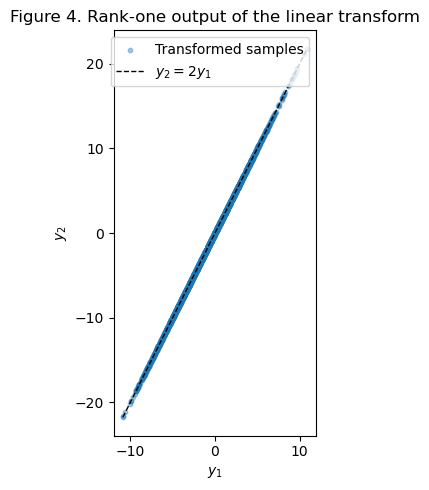

In [18]:
line_subset = Y_line[:3000]
ends = np.array([line_subset[:, 0].min(), line_subset[:, 0].max()])
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(*line_subset.T, s=10, alpha=0.38, label="Transformed samples")
ax.plot(ends, 2 * ends, "k--", lw=1, label=r"$y_2=2y_1$")
ax.set(xlabel=r"$y_1$", ylabel=r"$y_2$", title="Figure 4. Rank-one output of the linear transform")
ax.set_aspect("equal")
ax.legend()
fig.tight_layout()
plt.show()

**Interpretation of Figure 4.** The points vary along the line and have zero spread perpendicular to it. The first output component determines the second, leaving one random degree of freedom.

---
# Step 5. The multivariate Gaussian

For a $d$-dimensional observation $\mathbf{x}$, mean vector $\mu$, and positive definite covariance $\Sigma$,
$$
f(\mathbf{x})=\frac{\exp[-r^2(\mathbf{x})/2]}{(2\pi)^{d/2}\sqrt{\det\Sigma}},
\qquad r^2(\mathbf{x})=(\mathbf{x}-\mu)^T\Sigma^{-1}(\mathbf{x}-\mu).
$$
Here $r^2$ is the squared Mahalanobis radius. In `gaussian_pdf` we compute the determinant and solve $\Sigma z=\mathbf{x}-\mu$, then take the dot product with $\mathbf{x}-\mu$.

The normalization check integrates over six marginal standard deviations in each coordinate. A union bound gives an omitted probability of at most $4\Phi(-6)$ because either of the two coordinates can fall in either tail.

For $\mathbf{x}\sim\mathcal N(0,\Sigma)$, the change of variables $\mathbf{x}=\Sigma^{1/2}\mathbf{z}$ gives $r^2=\mathbf{z}^T\mathbf{z}$ with independent standard normal coordinates. In two dimensions $r^2\sim\chi^2_2$, with $P(r^2\le q)=1-e^{-q/2}$, so $q_p=-2\log(1-p)$ and the contour level is $f(0)e^{-q_p/2}$. Along a unit eigenvector $v_i$, $r^2(tv_i)=t^2/\lambda_i$, so the semiaxis length is $\sqrt{q_p\lambda_i}$ and the full axis length is twice that.

In [19]:
mu5 = np.zeros(2)
normal5 = stats.multivariate_normal(mean=mu5, cov=Sigma2)
points = np.array([[0, 0], [1.5, -0.5], [-3, 2], [2.5, 3.5], [-4, -1]])
ours = gaussian_pdf(points, mu5, Sigma2)
reference = normal5.pdf(points)
print(f"{'point':<17}{'ours':>15}{'SciPy':>15}{'relative diff':>16}")
for point, actual, expected in zip(points, ours, reference):
    print(f"{str(tuple(point.tolist())):<17}{actual:>15.8g}{expected:>15.8g}"
          f"{abs(actual-expected)/expected:>16.3e}")
print(f"Largest relative difference = {np.max(np.abs(ours-reference)/reference):.3e}")

bound = 6 * np.sqrt(Sigma2[0, 0])
mass, quad_error = integrate.dblquad(
    lambda y, x: gaussian_pdf([x, y], mu5, Sigma2)[0],
    -bound, bound, -bound, bound, epsabs=1e-10, epsrel=1e-10,
)
print(f"Integral over [{-bound:g}, {bound:g}] squared = {mass:.12f}")
print(f"Difference from 1 = {mass-1:.3e}, quadrature error estimate = {quad_error:.2e}, "
      f"omitted-mass bound = {4*stats.norm.sf(6):.2e}")

N5 = 10**4
X5 = rng5.multivariate_normal(mu5, Sigma2, size=N5)
probabilities = np.array([0.50, 0.90, 0.99])
q_levels = -2 * np.log1p(-probabilities)
density_levels = gaussian_pdf(mu5, mu5, Sigma2)[0] * np.exp(-q_levels / 2)
distances2 = np.sum(X5 * np.linalg.solve(Sigma2, X5.T).T, axis=1)
eigenvalues5 = np.linalg.eigvalsh(Sigma2)

rho5 = Sigma2[0, 1] / np.sqrt(Sigma2[0, 0] * Sigma2[1, 1])
print(f"rho = {rho5:g}, determinant = {np.linalg.det(Sigma2):g}")
print(f"Short-axis direction: (1,-1)/sqrt(2), angle {-45} degrees")
print(f"Long-axis direction:  (1, 1)/sqrt(2), angle {45} degrees")
print(f"{'prob.':>7}{'radius^2':>12}{'density':>12}{'short semi':>12}{'long semi':>12}"
      f"{'short axis':>12}{'long axis':>12}")
for p, q, level in zip(probabilities, q_levels, density_levels):
    short, long = np.sqrt(q * eigenvalues5)
    print(f"{p:>7.0%}{q:>12.4f}{level:>12.6f}{short:>12.4f}{long:>12.4f}"
          f"{2*short:>12.4f}{2*long:>12.4f}")
print(f"Enclosed fractions from {N5:,} samples")
print(comparison_header)
for p, q in zip(probabilities, q_levels):
    report_comparison(f"{p:.0%} contour", p, np.mean(distances2 <= q), np.sqrt(p * (1 - p) / N5))

point                       ours          SciPy   relative diff
(0.0, 0.0)           0.045944075    0.045944075       1.510e-16
(1.5, -0.5)          0.026729243    0.026729243       2.596e-16
(-3.0, 2.0)         0.0019362599   0.0019362599       1.120e-15
(2.5, 3.5)          0.0090469247   0.0090469247       1.917e-16
(-4.0, -1.0)        0.0052633001   0.0052633001       9.888e-16
Largest relative difference = 1.120e-15
Integral over [-12, 12] squared = 0.999999996054
Difference from 1 = -3.946e-09, quadrature error estimate = 8.88e-11, omitted-mass bound = 3.95e-09
rho = 0.5, determinant = 12
Short-axis direction: (1,-1)/sqrt(2), angle -45 degrees
Long-axis direction:  (1, 1)/sqrt(2), angle 45 degrees
  prob.    radius^2     density  short semi   long semi  short axis   long axis
    50%      1.3863    0.022972      1.6651      2.8841      3.3302      5.7681
    90%      4.6052    0.004594      3.0349      5.2565      6.0697     10.5130
    99%      9.2103    0.000459      4.2919     

<ipython-input-20-eca43bbaabc2>:17: MatplotlibDeprecationWarning: The width parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(width) instead.
  fig.tight_layout()
<ipython-input-20-eca43bbaabc2>:17: MatplotlibDeprecationWarning: The height parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(height) instead.
  fig.tight_layout()
<ipython-input-20-eca43bbaabc2>:17: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  fig.tight_layout()
<ipython-input-20-eca43bbaabc2>:17: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  fig.tight_layout()


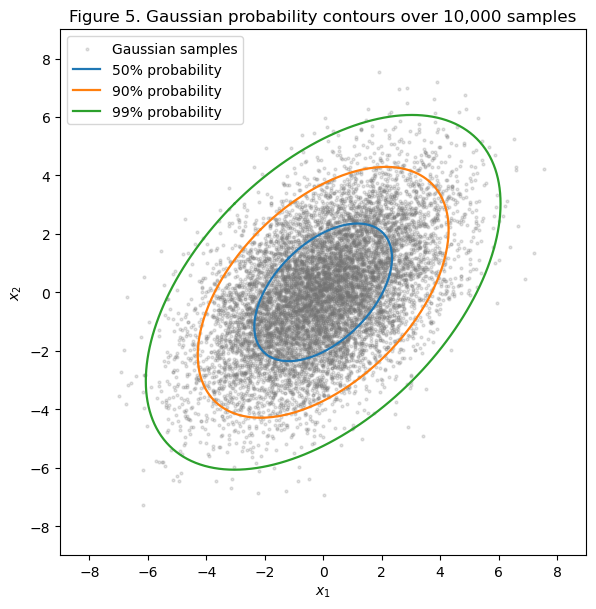

In [20]:
def draw_gaussian_contours(ax, covariance, samples, show_legend=True):
    values, vectors = np.linalg.eigh(covariance)
    angles = np.linspace(0, 2 * np.pi, 361)
    unit_circle = np.vstack([np.cos(angles), np.sin(angles)])
    ax.scatter(*samples.T, s=4, alpha=0.20, color="0.45", label="Gaussian samples")
    for p, q, color in zip(probabilities, q_levels, ("C0", "C1", "C2")):
        ellipse = vectors @ (np.sqrt(q * values)[:, None] * unit_circle)
        ax.plot(*ellipse, color=color, lw=1.6, label=f"{p:.0%} probability")
    ax.set(xlabel=r"$x_1$", ylabel=r"$x_2$", xlim=(-9, 9), ylim=(-9, 9))
    ax.set_aspect("equal")
    if show_legend:
        ax.legend(loc="upper left")

fig, ax = plt.subplots(figsize=(6.6, 6.2))
draw_gaussian_contours(ax, Sigma2, X5)
ax.set_title("Figure 5. Gaussian probability contours over 10,000 samples")
fig.tight_layout()
plt.show()

**Interpretation of Figure 5.** The cloud extends farthest along the positive diagonal, as expected for positive covariance. The three ellipses share that orientation and enclose progressively more of the cloud. The measured fractions and their binomial standard errors quantify how closely the counts match the intended probabilities.

   rho    det(Sigma)  minor/major axis
  0.00       16.0000            1.0000
  0.50       12.0000            0.5774
  0.90        3.0400            0.2294
  0.99        0.3184            0.0709


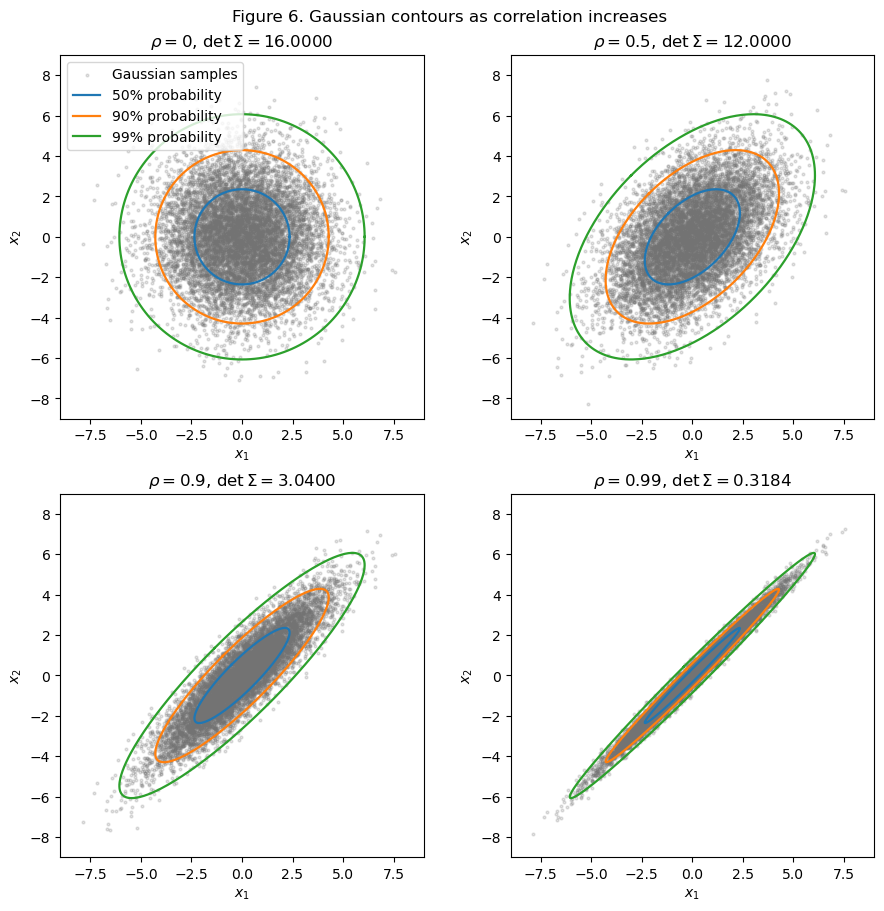

In [21]:
sweep_rhos = (0., 0.5, 0.9, 0.99)
# Reuse standard-normal draws to isolate the change in covariance across panels.
sweep_base = rng5.standard_normal((N5, 2))
fig, axes = plt.subplots(2, 2, figsize=(9, 9), layout="constrained")
print(f"{'rho':>6}{'det(Sigma)':>14}{'minor/major axis':>18}")
for ax, rho in zip(axes.flat, sweep_rhos):
    covariance = 4 * np.array([[1, rho], [rho, 1]])
    samples = sweep_base @ np.linalg.cholesky(covariance).T
    draw_gaussian_contours(ax, covariance, samples, show_legend=ax is axes[0, 0])
    det = np.linalg.det(covariance)
    ratio = np.sqrt((1 - rho) / (1 + rho))
    print(f"{rho:>6.2f}{det:>14.4f}{ratio:>18.4f}")
    ax.set_title(fr"$\rho={rho:g}$, $\det\Sigma={det:.4f}$")
fig.suptitle("Figure 6. Gaussian contours as correlation increases")
plt.show()

**Interpretation of Figure 6.** With equal variances the zero-correlation contours are circles. As $\rho$ grows, the variance along the negative diagonal, $4(1-\rho)$, tends to zero while the variance along the positive diagonal, $4(1+\rho)$, stays positive. Thus the determinant $16(1-\rho^2)$ tends to zero and the ellipse collapses toward $x_2=x_1$. The second measurement contributes progressively less new information about the pair because its conditional variance $4(1-\rho^2)$ vanishes in the limit.

---
# Step 6. Eigendecomposition, decorrelation and whitening

The sum and difference directions are eigenvectors because
$$
\Sigma\begin{bmatrix}1\\-1\end{bmatrix}
=2\begin{bmatrix}1\\-1\end{bmatrix},\qquad
\Sigma\begin{bmatrix}1\\1\end{bmatrix}
=6\begin{bmatrix}1\\1\end{bmatrix}.
$$
Normalize them by $\sqrt{2}$ and put them in the columns of $V$ in ascending eigenvalue order. Reversing an eigenvector's sign leaves its axis unchanged.

With $\Sigma=V\Lambda V^T$ and $V^TV=I$, the Step 4 rule gives
$$
\begin{aligned}
\operatorname{Cov}(V^T\mathbf{x})&=V^T\Sigma V
=(V^TV)\Lambda(V^TV)=\Lambda,\\
\operatorname{Cov}(W\mathbf{x})&=W\Sigma W^T
=\Lambda^{-1/2}\Lambda\Lambda^{-1/2}=I,
\qquad W=\Lambda^{-1/2}V^T.
\end{aligned}
$$
If $Q$ is a rotation, $Q^TQ=QQ^T=I$, so $(QW)\Sigma(QW)^T=QIQ^T=I$. In practice, the output coordinates can be rotated to suit the application while retaining unit variances and zero cross-covariances.

In [22]:
lam6, V6 = np.linalg.eigh(Sigma2)
print(f"Eigenvalues (short, long) = {lam6}")
print(f"Unit eigenvectors (columns):\n{V6}")
axis_angles = np.degrees(np.arctan2(V6[1], V6[0]))
axis_angles = (axis_angles + 90) % 180 - 90
print(f"Axis directions modulo 180 degrees = {axis_angles}")
print(f"Lengths of the scaled arrows = {np.sqrt(lam6)}")

decorrelated = X5 @ V6
W6 = whitening_matrix(Sigma2)
whitened = X5 @ W6.T
theta = np.pi / 6
Q6 = np.array([[np.cos(theta), -np.sin(theta)],
               [np.sin(theta), np.cos(theta)]])
W_rotated = Q6 @ W6
rotated = X5 @ W_rotated.T

print(f"W =\n{W6}")
print(f"Rotation of {np.degrees(theta):g} degrees gives Q =\n{Q6}")
print(f"Orthogonality residual = {np.linalg.norm(Q6 @ Q6.T - np.eye(2), 'fro'):.2e}")
for name, A, data, expected in [
    ("Decorrelated", V6.T, decorrelated, np.diag(lam6)),
    ("Whitened", W6, whitened, np.eye(2)),
    ("Rotated whitening", W_rotated, rotated, np.eye(2)),
]:
    _, estimated = sample_mean_cov(data)
    print(f"\n{name} covariance from {len(data):,} samples")
    print(f"Analytic transform residual = {np.linalg.norm(A @ Sigma2 @ A.T - expected, 'fro'):.2e}")
    report_covariance(expected, estimated, len(data))

N6 = 10**6
X6_4d = rng6.multivariate_normal(mu3, Sigma3, size=N6)
W6_4d = whitening_matrix(Sigma3)
_, S6_4d = sample_mean_cov(X6_4d @ W6_4d.T)
print(f"\nWhitening the Step 3 covariance with {N6:,} samples")
print(f"Analytic transform residual = {np.linalg.norm(W6_4d @ Sigma3 @ W6_4d.T - np.eye(4), 'fro'):.2e}")
report_covariance(np.eye(4), S6_4d, N6)

Eigenvalues (short, long) = [2. 6.]
Unit eigenvectors (columns):
[[-0.70710678  0.70710678]
 [ 0.70710678  0.70710678]]
Axis directions modulo 180 degrees = [-45.  45.]
Lengths of the scaled arrows = [1.41421356 2.44948974]
W =
[[-0.5         0.5       ]
 [ 0.28867513  0.28867513]]
Rotation of 30 degrees gives Q =
[[ 0.8660254 -0.5      ]
 [ 0.5        0.8660254]]
Orthogonality residual = 0.00e+00

Decorrelated covariance from 10,000 samples
Analytic transform residual = 9.93e-16
quantity             theory     estimate   est. - theory           SE
cov[1,1]                  2      2.00114       1.139e-03    2.829e-02
cov[1,2]                  0   -0.0397301      -3.973e-02    3.464e-02
cov[2,2]                  6      6.18484       1.848e-01    8.486e-02
Frobenius error = 0.193191

Whitened covariance from 10,000 samples
Analytic transform residual = 4.97e-16
quantity             theory     estimate   est. - theory           SE
cov[1,1]                  1      1.00057       5.694e-04  

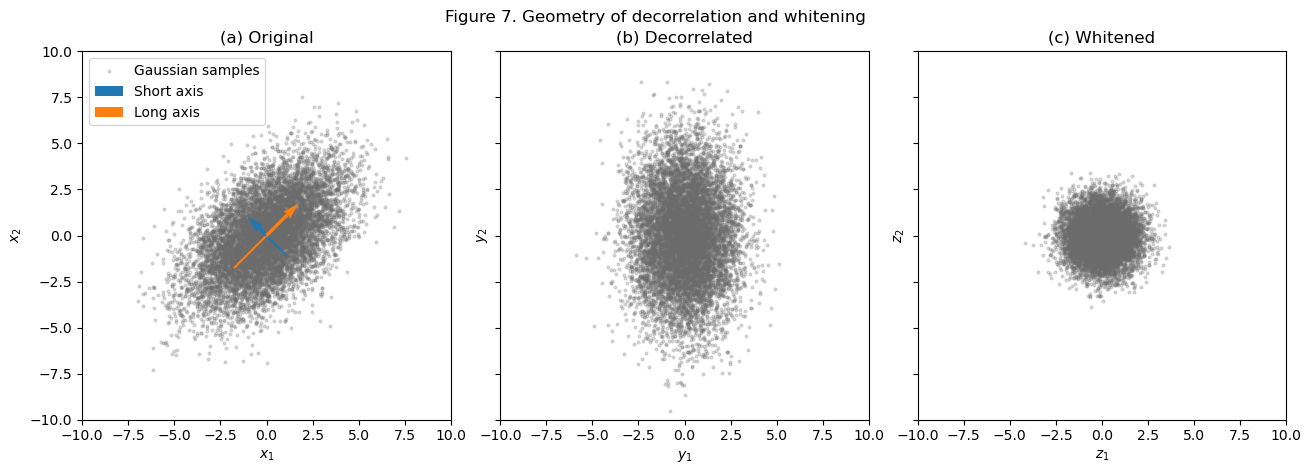

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6), sharex=True, sharey=True, layout="constrained")
for ax, data, title, labels in [
    (axes[0], X5, "(a) Original", (r"$x_1$", r"$x_2$")),
    (axes[1], decorrelated, "(b) Decorrelated", (r"$y_1$", r"$y_2$")),
    (axes[2], whitened, "(c) Whitened", (r"$z_1$", r"$z_2$")),
]:
    ax.scatter(*data.T, s=4, alpha=0.23, color="0.42", label="Gaussian samples")
    ax.set(xlabel=labels[0], ylabel=labels[1], title=title)
    ax.set_aspect("equal")

limit = np.ceil(max(np.abs(data).max() for data in (X5, decorrelated, whitened)))
axes[0].set(xlim=(-limit, limit), ylim=(-limit, limit))
for length, vector, color, label in zip(np.sqrt(lam6), V6.T, ("C0", "C1"),
                                         ("Short axis", "Long axis")):
    dx, dy = length * vector
    axes[0].quiver(0, 0, dx, dy, angles="xy", scale_units="xy", scale=1,
                   width=0.009, color=color, label=label, zorder=4)
    axes[0].plot([-dx, 0], [-dy, 0], color=color, lw=1.5)
axes[0].legend(loc="upper left")
fig.suptitle("Figure 7. Geometry of decorrelation and whitening")
plt.show()

**Interpretation of Figure 7.** The eigenvector arrows point along the short and long axes of the original cloud. Decorrelation aligns those axes with the coordinate axes while preserving their unequal spreads. Whitening then gives a nearly circular cloud, with the reported covariance differences on the scale of their sampling standard errors.

---
# Step 7. The conditional Gaussian
For the jointly Gaussian pair $(X,Y)$ with zero mean and $\Sigma=\begin{bmatrix}4&2\\2&4\end{bmatrix}$, the marginal $X$ has variance $4$. The joint Gaussian density factors as $f_{XY}(x,y)=f_X(x)f_{Y|X}(y|x)$. Completing the square in its exponent gives
$$\frac{x^2}{4}+\frac{(y-x/2)^2}{3}=\frac{4x^2-4xy+4y^2}{12},$$
so
$$\boxed{Y\mid X=x\sim\mathcal N(x/2,3)},\qquad f_{Y|X}(y|x)=\frac{1}{\sqrt{6\pi}}\exp\!\left[-\frac{(y-x/2)^2}{6}\right].$$
In general, for $\begin{bmatrix}X\\Y\end{bmatrix}\sim\mathcal N\left(\begin{bmatrix}\mu_X\\\mu_Y\end{bmatrix},\begin{bmatrix}\Sigma_{XX}&\Sigma_{XY}\\\Sigma_{YX}&\Sigma_{YY}\end{bmatrix}\right)$,
$$Y\mid X=x\sim\mathcal N\left(\mu_Y+\Sigma_{YX}\Sigma_{XX}^{-1}(x-\mu_X),\ \Sigma_{YY}-\Sigma_{YX}\Sigma_{XX}^{-1}\Sigma_{XY}\right).$$
Here $\Sigma_{YX}=2$, $\Sigma_{XX}=4$, $\Sigma_{YY}=4$, yielding conditional mean $2x/4=x/2$ and variance $4-2^2/4=3$. We use a linear solve rather than an explicit matrix inverse in code.

Step 7: N=1,000,000; fitted conditional-mean slope=0.499360 +/- 0.000878; expected=0.500000; difference=-0.000640
Mean binned conditional variance=2.997178 +/- 0.022448; expected=3.000000; difference=-0.002822


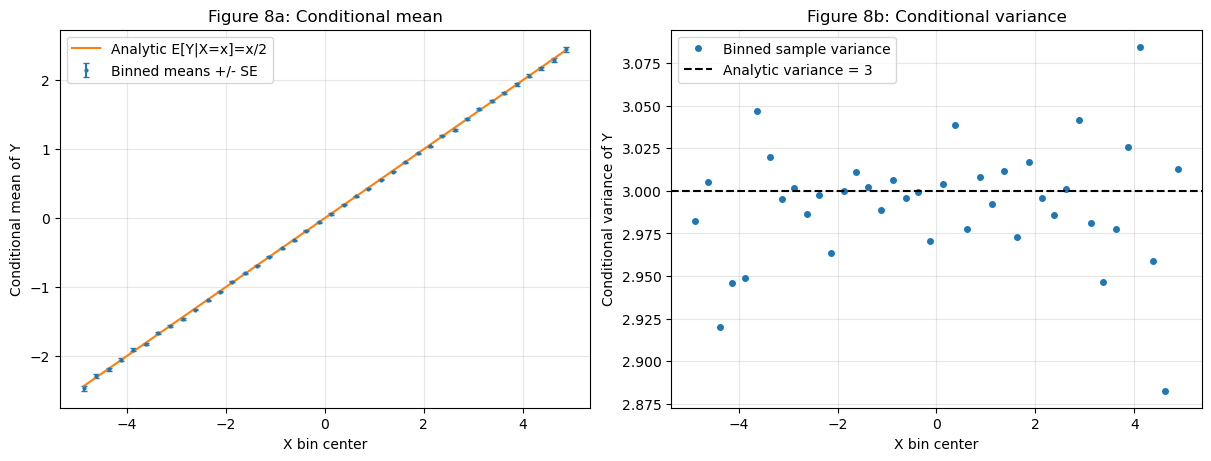

In [24]:
# One million independent samples, using the Step 7 stream spawned in the setup cell.
N7 = 1_000_000
xy7 = rng7.multivariate_normal(np.zeros(2), Sigma2, size=N7)
x7, y7 = xy7.T
edges7 = np.linspace(-5, 5, 41)
centers7 = (edges7[1:] + edges7[:-1]) / 2
bin7 = np.searchsorted(edges7, x7, side="right") - 1
valid7 = (bin7 >= 0) & (bin7 < len(centers7))
counts7 = np.bincount(bin7[valid7], minlength=len(centers7))
sums7 = np.bincount(bin7[valid7], weights=y7[valid7], minlength=len(centers7))
sumsq7 = np.bincount(bin7[valid7], weights=y7[valid7]**2, minlength=len(centers7))
mean7 = sums7 / np.maximum(counts7, 1)
var7 = (sumsq7 - sums7**2 / np.maximum(counts7, 1)) / np.maximum(counts7-1, 1)
keep7 = counts7 >= 200
se_mean7 = np.sqrt(var7[keep7] / counts7[keep7])
# Weighted least squares; bin centers induce a small finite-width approximation error.
fit7, covfit7 = np.polyfit(centers7[keep7], mean7[keep7], 1, w=1/se_mean7, cov=True)
slope7, slope_se7 = fit7[0], np.sqrt(covfit7[0,0])
variance_mean7 = np.average(var7[keep7], weights=counts7[keep7])
variance_se7 = np.sqrt(np.average(2*var7[keep7]**2/(counts7[keep7]-1), weights=(counts7[keep7]/counts7[keep7].sum())**2))
print(f"Step 7: N={N7:,}; fitted conditional-mean slope={slope7:.6f} +/- {slope_se7:.6f}; expected=0.500000; difference={slope7-.5:+.6f}")
print(f"Mean binned conditional variance={variance_mean7:.6f} +/- {variance_se7:.6f}; expected=3.000000; difference={variance_mean7-3:+.6f}")
fig, ax = plt.subplots(1,2,figsize=(12,4.5),layout="constrained")
ax[0].errorbar(centers7[keep7],mean7[keep7],yerr=se_mean7,fmt=".",ms=4,capsize=2,label="Binned means +/- SE")
ax[0].plot(centers7,centers7/2,label="Analytic E[Y|X=x]=x/2")
ax[0].set(xlabel="X bin center",ylabel="Conditional mean of Y",title="Figure 8a: Conditional mean")
ax[0].legend();ax[0].grid(alpha=.3)
ax[1].plot(centers7[keep7],var7[keep7],"o",ms=4,label="Binned sample variance")
ax[1].axhline(3,color="black",ls="--",label="Analytic variance = 3")
ax[1].set(xlabel="X bin center",ylabel="Conditional variance of Y",title="Figure 8b: Conditional variance")
ax[1].legend();ax[1].grid(alpha=.3)
plt.show()

**Interpretation of Figure 8.** The binned conditional means follow the analytic line $E[Y|X=x]=0.5x$; the printed slope, its standard error, and its difference from $0.5$ quantify the agreement. The conditional variance stays near $3$ for all well-populated bins, with fluctuations due to finite sampling. The *constant* conditional variance and linear conditional mean are special properties of jointly Gaussian data. Because the Gaussian conditional mean is linear, the minimum-mean-square-error predictor is itself linear; therefore the best linear estimator in Step 8 is also the unrestricted MMSE estimator under the stated joint Gaussian model.

---
# Step 8. Fusing two correlated sensors
Let $S\sim\mathcal N(0,4)$ and $X_1=S+N_1$, $X_2=S+N_2$, where $S$ is independent of zero-mean Gaussian noise $N$ with covariance $\Sigma_N=\begin{bmatrix}1&c\\c&2\end{bmatrix}$. Write $\mathbf1=[1,1]^T$, $\mathbf x=\mathbf1 S+\mathbf N$. Then
$$\Sigma_{xx}=E[\mathbf x\mathbf x^T]=4\mathbf1\mathbf1^T+\Sigma_N=\begin{bmatrix}5&4+c\\4+c&6\end{bmatrix},\quad\Sigma_{sx}=E[\mathbf x S]=4\mathbf1.$$
For $\hat S=\mathbf w^T\mathbf x$, expanding $E[(S-\mathbf w^T\mathbf x)^2]$ gives
$$J(\mathbf w)=4-2\mathbf w^T\Sigma_{sx}+\mathbf w^T\Sigma_{xx}\mathbf w.$$
Setting $\nabla J=0$ yields $\Sigma_{xx}\mathbf w=\Sigma_{sx}$ and thus
$$\boxed{\mathbf w=\Sigma_{xx}^{-1}\Sigma_{sx}},\qquad\boxed{\operatorname{MMSE}=4-\Sigma_{sx}^T\Sigma_{xx}^{-1}\Sigma_{sx}}.$$
The noise covariance has eigenvalues nonnegative exactly when $1>0$ and $\det\Sigma_N=2-c^2\ge0$, so $|c|\le\sqrt2$ is positive semidefinite; the interior $|c|<\sqrt2$ is positive definite and is used for the plot and simulations.
Writing $D=\det\Sigma_{xx}=30-(4+c)^2=14-8c-c^2$, Cramer's rule gives
$$w_1=\frac{4(2-c)}{D},\qquad\boxed{w_2=\frac{4(1-c)}{D}},\qquad\boxed{\operatorname{MMSE}(c)=\frac{4(2-c^2)}{14-8c-c^2}}.$$
Thus $w_2$ crosses zero at $c=1$. Differentiating,
$$\operatorname{MMSE}'(c)=\frac{32(c-1)(c-2)}{(14-8c-c^2)^2}.$$
Since $c<\sqrt2<2$, this derivative is positive below $c=1$ and negative above $c=1$: **$c=1$ is a maximum**, not a minimum. The best-single-sensor Bayesian estimate uses $\hat S=(4/5)X_1$ and has MSE $4/5=0.8$. Naive equal weighting $\hat S=(X_1+X_2)/2$ has MSE $(3+2c)/4$.

Step 8: c       w1         w2        MMSE       single      equal
-1.4   0.585198   0.413081   0.006885   0.800000   0.050000
-1.0   0.571429   0.380952   0.190476   0.800000   0.250000
-0.5   0.563380   0.338028   0.394366   0.800000   0.500000
+0.0   0.571429   0.285714   0.571429   0.800000   0.750000
+0.5   0.615385   0.205128   0.717949   0.800000   1.000000
+1.0   0.800000   0.000000   0.800000   0.800000   1.250000
+1.2   1.081081  -0.270270   0.756757   0.800000   1.350000
+1.4   2.857143  -1.904762   0.190476   0.800000   1.450000
At c=1.4, Var(X1-X2)=3-2c=0.200000
At c=-1 and c=+1.4, MMSE=0.190476 and 0.190476
Monte Carlo c=0.8: N=1,000,000, analytic MMSE=0.781609, simulated MSE=0.782734, difference=+0.001125, SE=0.001108
Monte Carlo c=1.4: N=1,000,000, analytic MMSE=0.190476, simulated MSE=0.190888, difference=+0.000412, SE=0.000270


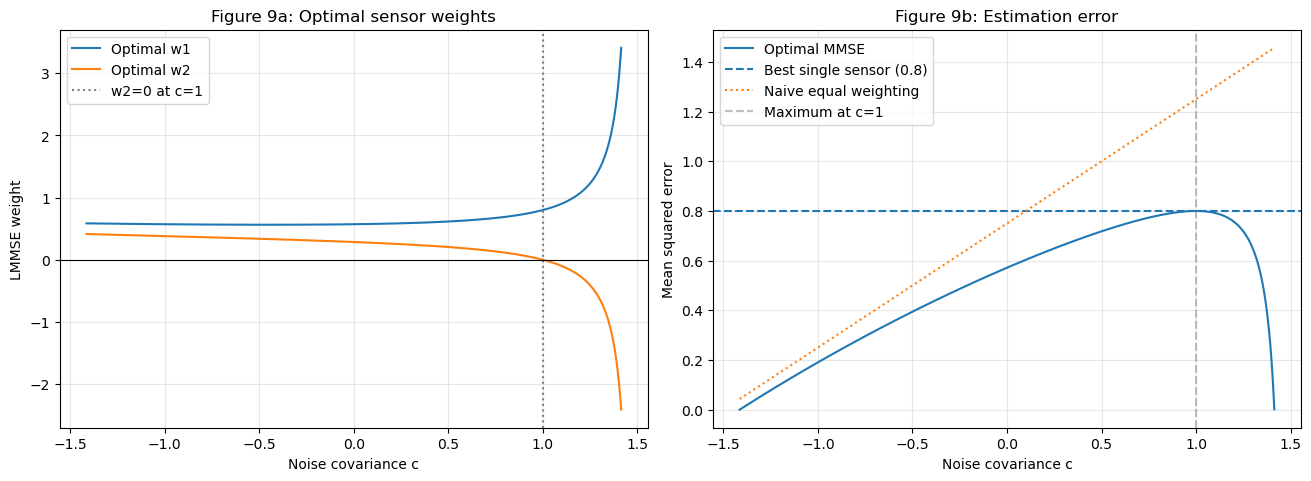

In [25]:
# Analytic weights and baseline comparison; reuse mp3lib.py's lmmse_weights.
c_values8 = [-1.4,-1.,-.5,0.,.5,1.,1.2,1.4]
def sensor_stats8(c):
    noise_cov = np.array([[1.,c],[c,2.]])
    sxx = 4*np.ones((2,2)) + noise_cov
    sx = 4*np.ones(2)
    w = lmmse_weights(sxx,sx)
    mse = 4 - sx @ w
    return w, float(mse)
print("Step 8: c       w1         w2        MMSE       single      equal")
for c in c_values8:
    w,mse=sensor_stats8(c)
    print(f"{c:+.1f}  {w[0]:9.6f}  {w[1]:9.6f}  {mse:9.6f}  {0.8:9.6f}  {(3+2*c)/4:9.6f}")
print(f"At c=1.4, Var(X1-X2)=3-2c={3-2*1.4:.6f}")
print(f"At c=-1 and c=+1.4, MMSE={sensor_stats8(-1)[1]:.6f} and {sensor_stats8(1.4)[1]:.6f}")
# Monte Carlo: same Step 8 generator; two distinct draws from its stream.
N8=1_000_000
for c in (0.8,1.4):
    s = rng8.normal(0,2,size=N8)
    noise = rng8.multivariate_normal([0,0],[[1,c],[c,2]],size=N8)
    x = noise+s[:,None]
    w, analytic=sensor_stats8(c)
    sq=(s-x@w)**2
    empirical=sq.mean()
    se=sq.std(ddof=1)/np.sqrt(N8)
    print(f"Monte Carlo c={c:.1f}: N={N8:,}, analytic MMSE={analytic:.6f}, simulated MSE={empirical:.6f}, difference={empirical-analytic:+.6f}, SE={se:.6f}")
cs8=np.linspace(-np.sqrt(2)+1e-4,np.sqrt(2)-1e-4,1200)
w8=np.array([sensor_stats8(c)[0] for c in cs8])
mse8=np.array([sensor_stats8(c)[1] for c in cs8])
fig, ax=plt.subplots(1,2,figsize=(13,4.7),layout="constrained")
ax[0].plot(cs8,w8[:,0],label="Optimal w1")
ax[0].plot(cs8,w8[:,1],label="Optimal w2")
ax[0].axvline(1,color="gray",ls=":",label="w2=0 at c=1")
ax[0].axhline(0,color="black",lw=.8)
ax[0].set(xlabel="Noise covariance c",ylabel="LMMSE weight",title="Figure 9a: Optimal sensor weights")
ax[0].legend();ax[0].grid(alpha=.3)
ax[1].plot(cs8,mse8,label="Optimal MMSE")
ax[1].axhline(.8,ls="--",label="Best single sensor (0.8)")
ax[1].plot(cs8,(3+2*cs8)/4,ls=":",label="Naive equal weighting")
ax[1].axvline(1,color="gray",ls="--",alpha=.5,label="Maximum at c=1")
ax[1].set(xlabel="Noise covariance c",ylabel="Mean squared error",title="Figure 9b: Estimation error")
ax[1].legend();ax[1].grid(alpha=.3)
plt.show()

**Interpretation of Figure 9.** The second sensor's optimal weight decreases to zero at $c=1$ and becomes negative for $c>1$. Subtracting a small amount of the second measurement removes common noise: the signal cancels in $X_1-X_2=N_1-N_2$, whose variance is $1+2-2c=3-2c$ (only $0.2$ at $c=1.4$). This noise-difference information allows the estimator to cancel interference while retaining the signal through unequal weights.

The MMSE increases from low values at negative $c$ to its **global maximum $0.8$ at $c=1$**, then decreases sharply as $c$ approaches $+\sqrt2$. At both endpoints $c\to\pm\sqrt2$ the noise covariance becomes singular and the limiting MMSE tends to zero; near-perfect noise correlation can therefore be useful if its structure is known precisely. At $c=0$, MMSE is $0.571429$, versus $0.190476$ at $c=1.4$; even though the noises are more correlated, the difference measurement provides a way to cancel their shared component. The printed Monte Carlo estimates and standard errors test this theory at $c=0.8$ and $1.4$.

**Systems recommendation.** I would not automatically prefer independent sensors: highly correlated sensors can outperform them if their noise covariance is stable, accurately estimated, and exploitable by the optimal weighting. Before specifying them, I would require measurements of the actual cross-covariance over temperature, interference, and operating conditions, plus an assessment of how sensitive the estimator is to covariance-estimation errors. Otherwise the more robust independent-noise design may be safer.

In [26]:
elapsed = time.perf_counter() - t_start
print(f"Total runtime: {elapsed:.1f} s")

Total runtime: 30.0 s
